# Channel Ablation per Object: Faster R-CNN version (RGB vs YGB vs LGB)

Set `DATASET_NAME` in the first code cell (**SSL** by default).

This is the Faster R-CNN twin of your YOLO notebook `v8-SIMD-RYL(perO)`. **No training happens here.** It loads the three `best.pth` files, damages the *test* images channel by channel, and measures what happens **per object**.

### YOLO -> Faster R-CNN: what changes

| | YOLO notebook | This notebook |
|---|---|---|
| Model loading | `YOLO(best.pt)` | build Faster R-CNN, `load_state_dict(best.pth)` |
| Image reading | `cv2.imread` -> **BGR**, passed as is (Ultralytics flips it once) | `cv2.imread` + **`cv2.cvtColor(BGR2RGB)`** -> **RGB** (torchvision never flips) |
| Channel order | index 0 = B, 1 = G, **2 = R/Y/L** | index **0 = R/Y/L**, 1 = G, 2 = B |
| Class ids | 0..N-1 | model outputs 1..N -> we subtract 1 |
| Score | sigmoid confidence | **softmax probability** (not on the same scale as YOLO) |
| Prediction threshold | `conf=0.001` | `box_score_thresh=0.001` (same idea) |

**Why `cvtColor` is needed here but was wrong for YOLO:** `cv2.imread` always returns BGR. Ultralytics treats a numpy array as BGR and flips it itself, so any extra `cvtColor` makes a second flip (the old YOLO bug). torchvision never flips: the tensor must already be RGB, because that is how the training notebook fed it (`PIL ... convert("RGB")`). One `cvtColor(BGR2RGB)` therefore gives exactly the training pixels. A check cell below proves this (PIL vs cv2 difference) and also shows in which channel the L / Y values are stored.

**Channel-order warning:** the YOLO tables called "Mask R" index 2 (BGR array). Here index 0 is R/Y/L. The configs below are named by the *real channel* (R, G, B, Y, L), so "Mask Y" here means the same thing as "Mask Y" in YOLO.

### What is measured (same as your YOLO notebook)
For every ground-truth object (one box = one sample):
* look at predictions of the **same class** with **IoU >= 0.5** with that box
* score = the **highest** confidence among them, or **0** if there is none
* `MeanConf` = average of those scores per class, `Recall` = fraction of objects with at least one match

*Example:* a car box, the model has two "car" predictions overlapping it with IoU 0.7 (conf 0.9) and 0.55 (conf 0.4). Score = 0.9. If none reaches IoU 0.5, score = 0 and the object counts as a miss.

### DIP theory: what "masking a channel" is
A colour pixel is a vector `(c0, c1, c2)`. Masking is a **per-pixel linear map** with a diagonal matrix:
* mask channel 0: `diag(0,1,1)`. Example `(200,100,50) -> (0,100,50)`
* keep only channel 0: `diag(1,0,0)`. Example `(200,100,50) -> (200,0,0)`
* `FILL_MODE="mean"` replaces the removed channel by its image mean instead of 0 (keeps the overall brightness level, removes spatial detail).

**Why a big drop means "the model depends on this channel":** the network was trained with all 3 channels, so removing one is a test-time distribution shift. The drop is a *sensitivity* measure, not proof the channel is "useful" in general. Note also that the network normalises `(x - mean)/std` internally, so a zeroed channel becomes about -2.1 std, which is far off the training range. That is the same behaviour as in your YOLO run, so the comparison stays consistent.


In [2]:
import os, json, time
from pathlib import Path
import numpy as np
import cv2
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# ---------------- paths (same as your training notebook) ----------------
BASE_DIR = Path(r"C:\Users\DELL\Desktop\c")
DATASET_NAME = "SIMD"             # "SSL" (4 classes) or "SIMD" (15 classes); must match the notebook you trained with
DATASET_CLASSES = {
    "SSL":  ['airplane', 'boat', 'car', 'ship'],
    "SIMD": ['car', 'truck', 'van', 'longvehicle', 'bus', 'airliner', 'propeller', 'trainer',
             'chartered', 'fighter', 'other', 'stairtruck', 'pushbacktruck', 'helicopter', 'boat'],
}
DATASETS = {c: BASE_DIR / f"{DATASET_NAME}_{c}" for c in ("RGB", "YGB", "LGB")}
RUNS_DIR = BASE_DIR / "runs_frcnn_neutral"
IMBALANCE_MODE = "ce"            # MUST match the mode you trained with (it is in the run-folder name)
MODELS_TO_RUN = ["RGB", "YGB", "LGB"]   # models whose best.pth does not exist yet are skipped

# ---------------- model settings (must match training) ----------------
CLASS_NAMES = DATASET_CLASSES[DATASET_NAME]
NUM_CLASSES = len(CLASS_NAMES) + 1          # +1 background
MIN_SIZE, MAX_SIZE = 800, 1333
USE_AMP = False     # keep False: full fp32 on GPU, so the numbers are comparable with the earlier CPU run. Use the same value for all models.

# ---------------- ablation settings (same as YOLO notebook) ----------------
PREDICT_CONF = 0.001     # one value, used everywhere (no detections filtered out)
IOU_THR      = 0.5
FILL_MODE    = "zero"    # "zero" or "mean"
CHUNK        = 4         # images per forward pass; lower to 2 or 1 if CUDA out-of-memory

# index 0 = R/Y/L, 1 = G, 2 = B  (cv2.imread gives BGR, we convert to RGB with cvtColor in read_rgb)
channel_names = {
    "RGB": {0: "R", 1: "G", 2: "B"},
    "YGB": {0: "Y", 1: "G", 2: "B"},
    "LGB": {0: "L", 1: "G", 2: "B"},
}
CLASS_IDS = list(range(len(CLASS_NAMES)))


device: cuda


## Helper functions
* `apply_channel_mask`: the diagonal-matrix idea above, written with NumPy slicing (`out[:, :, c] = 0` zeroes channel `c` for all pixels at once).
* `get_gt_boxes`: converts YOLO labels (`cx, cy, w, h` in 0..1) to pixel corners `x1,y1,x2,y2`. *Example:* image 1000x800, `cx=.5, cy=.5, w=.1, h=.2` gives `450, 320, 550, 480`.
* `iou`: intersection / union of two boxes (same function as in the training notebook).
* `load_model`: builds the empty architecture, swaps in the new head (background + your classes), loads your trained weights. No COCO download needed here, because `best.pth` already contains everything.


In [3]:
def find_split_dir(root, split):
    for p in Path(root).iterdir():
        if p.is_dir() and p.name.lower() == split.lower():
            return p
    raise FileNotFoundError(f"No '{split}' folder inside {root}")

def read_rgb(path):
    """cv2.imread returns BGR; ONE cvtColor gives RGB = the same pixels the training notebook used."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(f"cv2 could not read {path}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

def apply_channel_mask(img, ch, kind, fill="zero"):
    """img: H x W x 3 uint8 in RGB order. ch: 0,1,2. kind: 'zero_ch' or 'keep_only'."""
    out = img.copy()
    def fill_ch(c):
        out[:, :, c] = 0 if fill == "zero" else int(round(img[:, :, c].mean()))
    if kind == "zero_ch":
        fill_ch(ch)
    elif kind == "keep_only":
        for c in range(3):
            if c != ch:
                fill_ch(c)
    return out

def get_gt_boxes(lbl_path, W, H):
    boxes = []
    if not Path(lbl_path).exists():
        return boxes
    for line in Path(lbl_path).read_text().splitlines():
        p = line.split()
        if len(p) < 5:
            continue
        c = int(float(p[0]))
        if not (0 <= c < len(CLASS_NAMES)):
            continue
        xc, yc, w, h = map(float, p[1:5])
        boxes.append((c, ((xc - w/2)*W, (yc - h/2)*H, (xc + w/2)*W, (yc + h/2)*H)))
    return boxes

def iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    ua = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / ua if ua > 0 else 0.0

def load_model(ckpt):
    model = fasterrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None,
                                       min_size=MIN_SIZE, max_size=MAX_SIZE,
                                       box_score_thresh=PREDICT_CONF, box_detections_per_img=300)
    in_f = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_f, NUM_CLASSES)
    model.load_state_dict(torch.load(ckpt, map_location="cpu", weights_only=True))
    return model.to(device).eval()

@torch.no_grad()
def predict_batch(model, imgs):
    """imgs: list of H x W x 3 uint8 (RGB). Returns, per image, a list of (class0..14, score, [x1,y1,x2,y2])."""
    ts = [torch.from_numpy(i).permute(2, 0, 1).float().div(255).to(device) for i in imgs]
    with torch.autocast(device_type="cuda", enabled=USE_AMP and device.type == "cuda"):
        outs = model(ts)
    return [list(zip((o["labels"] - 1).tolist(), o["scores"].float().tolist(), o["boxes"].float().tolist()))
            for o in outs]

# ---- the 7 configurations (same as YOLO) ----
mask_configs = [{"kind": "none", "ch": None}]
mask_configs += [{"kind": "zero_ch",   "ch": c} for c in range(3)]
mask_configs += [{"kind": "keep_only", "ch": c} for c in range(3)]

def cfg_label(model_name, cfg):
    if cfg["kind"] == "none":
        return "Full (Baseline)"
    n = channel_names[model_name][cfg["ch"]]
    return f"Mask {n}" if cfg["kind"] == "zero_ch" else f"Only {n}"

# ---- quick self-test of the helpers (pure NumPy, runs instantly) ----
_px = np.array([[[200, 100, 50]]], dtype=np.uint8)
assert apply_channel_mask(_px, 0, "zero_ch")[0, 0].tolist()   == [0, 100, 50]
assert apply_channel_mask(_px, 0, "keep_only")[0, 0].tolist() == [200, 0, 0]
assert abs(iou((0, 0, 10, 10), (5, 0, 15, 10)) - 1/3) < 1e-9
print("helpers OK: mask (200,100,50) -> (0,100,50) | keep-only -> (200,0,0) | IoU = 0.333")


helpers OK: mask (200,100,50) -> (0,100,50) | keep-only -> (200,0,0) | IoU = 0.333


## Test image list
Same rule as YOLO: use images that exist in all three folders and have a label file. Ground truth is read **once** (labels are identical across colour spaces, only the pixels differ).


In [4]:
test_dirs = {m: find_split_dir(DATASETS[m], "test") / "images" for m in DATASETS}
lbl_dir   = find_split_dir(DATASETS["RGB"], "test") / "labels"
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

all_images = sorted(p.name for p in test_dirs["RGB"].iterdir() if p.suffix.lower() in EXTS)
img_list = [n for n in all_images
            if all((test_dirs[m] / n).exists() for m in DATASETS)
            and (lbl_dir / (Path(n).stem + ".txt")).exists()]

gt_cache = {}
for n in img_list:
    W, H = Image.open(test_dirs["RGB"] / n).size
    g = get_gt_boxes(lbl_dir / (Path(n).stem + ".txt"), W, H)
    if g:
        gt_cache[n] = g
img_list = [n for n in img_list if n in gt_cache]
print(f"Using {len(img_list)} images, {sum(len(v) for v in gt_cache.values())} ground-truth objects")


Using 500 images, 4628 ground-truth objects


## Sanity checks (run once, before the main loop)

**Check 1: cv2 pipeline = training pipeline.** The training notebook read images with `PIL ... convert("RGB")`. `read_rgb` (cv2 + one `cvtColor`) must give the same pixels. Expected max difference: 0 (or 1-2, because JPEG decoders can round differently). A big number means a channel-order problem: stop and do not run the main loop.

**Check 2: where is L (or Y) stored?** We recompute OKLab L from the RGB image and compare it with each channel of the LGB image (same for Y with the YGB image). The channel with the smallest error holds it. It must be channel **0** in the RGB-ordered array, which is what `channel_names` assumes.


In [5]:
# ---- Check 1: cv2 (read_rgb) vs PIL (what training used) ----
for m in DATASETS:
    worst = 0
    for n in img_list[:10]:
        a = np.asarray(Image.open(test_dirs[m] / n).convert("RGB")).astype(int)
        b = read_rgb(test_dirs[m] / n).astype(int)
        worst = max(worst, np.abs(a - b).max())
    print(f"[{m}] max |PIL - cv2| over 10 images: {worst}")
    assert worst <= 3, f"{m}: cv2 and PIL disagree -> channel order problem, do NOT run the main loop"

# ---- Check 2: which channel holds L / Y ? ----
def oklab_L(rgb_u8):
    c = rgb_u8.astype(np.float64) / 255
    lin = np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)
    M1 = np.array([[0.4122214, 0.5363325, 0.0514459],
                   [0.2119034, 0.6806995, 0.1073969],
                   [0.0883024, 0.2817188, 0.6299787]])
    return np.cbrt(lin @ M1.T) @ np.array([0.2104542, 0.7936177, -0.0040720])

def luma_Y(rgb_u8):
    c = rgb_u8.astype(np.float64)
    return 0.299 * c[..., 0] + 0.587 * c[..., 1] + 0.114 * c[..., 2]

n   = img_list[0]
rgb = read_rgb(test_dirs["RGB"] / n)
for name, folder, f in [("L", "LGB", lambda x: oklab_L(x) * 255), ("Y", "YGB", luma_Y)]:
    conv = read_rgb(test_dirs[folder] / n)
    ref  = f(rgb)
    errs = [float(np.abs(conv[..., k] - ref).mean()) for k in range(3)]
    print(f"{name} in {folder}: mean abs error per channel 0/1/2 = {[round(e, 2) for e in errs]}  -> stored in channel {int(np.argmin(errs))}")
    if int(np.argmin(errs)) != 0:
        msg = f"{name} is NOT in channel 0 -> fix channel_names before running"
        if name == "L":
            raise AssertionError(msg)
        print("WARNING:", msg, "(Y may be stored in studio range 16-235 if rgb2ycbcr was used; check the YGB conversion script)")
print("checks OK")


[RGB] max |PIL - cv2| over 10 images: 0
[YGB] max |PIL - cv2| over 10 images: 0
[LGB] max |PIL - cv2| over 10 images: 0
L in LGB: mean abs error per channel 0/1/2 = [1.58, 24.31, 30.71]  -> stored in channel 0
Y in YGB: mean abs error per channel 0/1/2 = [1.09, 1.51, 7.22]  -> stored in channel 0
checks OK


## See it first: what the network receives
One test image in the RGB folder under all 7 configurations. If the pictures look like what you expect (for example "Only R" is a red-only image), the masking is correct. The Y/L versions look the same way for the YGB/LGB folders, because channel 0 simply holds Y or L there.


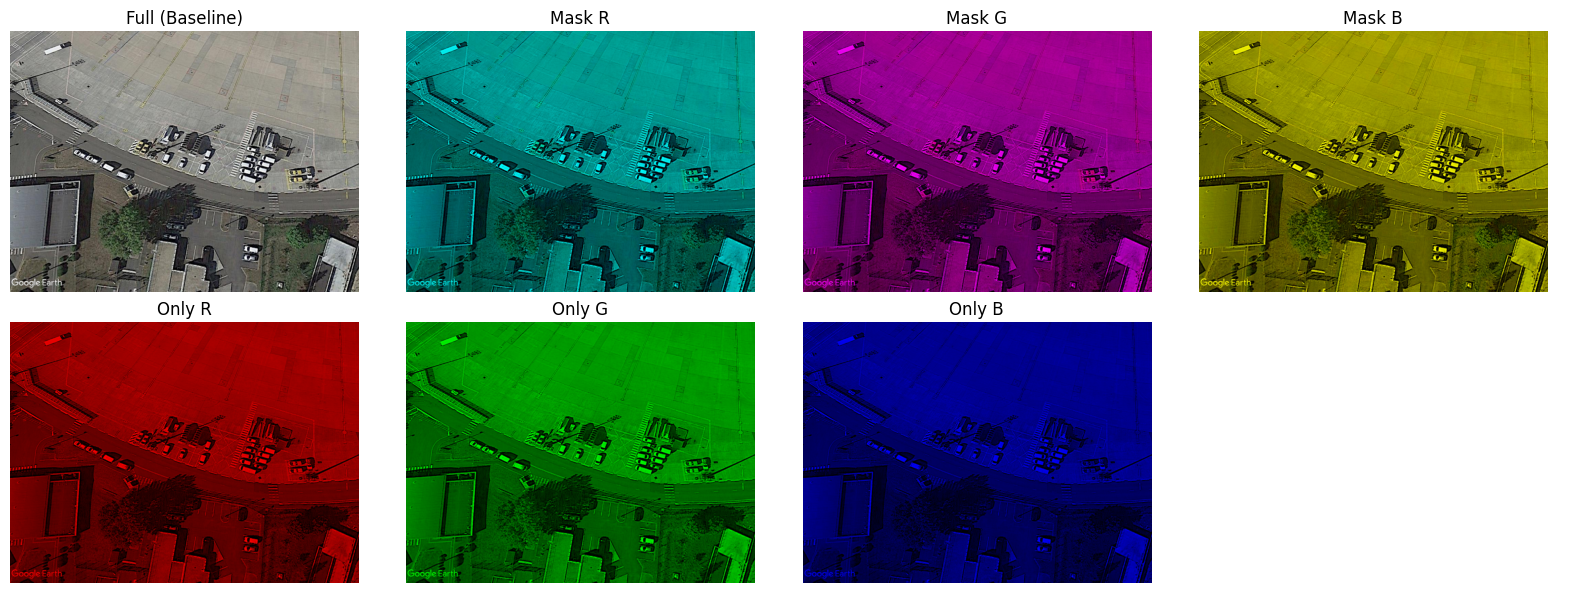

In [6]:
import matplotlib.pyplot as plt
_name = img_list[0]
_img = read_rgb(test_dirs["RGB"] / _name)
fig, axs = plt.subplots(2, 4, figsize=(16, 6))
for ax, cfg in zip(axs.ravel(), mask_configs):
    ax.imshow(apply_channel_mask(_img, cfg["ch"], cfg["kind"], FILL_MODE) if cfg["kind"] != "none" else _img)
    ax.set_title(cfg_label("RGB", cfg)); ax.axis("off")
axs.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()


## Main loop
For each model (one at a time to save VRAM) and each test image, the 7 versions of the image are pushed through the network in chunks of `CHUNK`, and every ground-truth object is scored as described above. A progress bar shows speed and ETA (test images x 7 versions x 3 models). A model whose `best.pth` does not exist yet is skipped, so you can run this after only RGB has finished.


In [7]:
results = {m: {cfg_label(m, c): {k: [] for k in CLASS_IDS} for c in mask_configs} for m in MODELS_TO_RUN}
tp      = {m: {cfg_label(m, c): {k: 0  for k in CLASS_IDS} for c in mask_configs} for m in MODELS_TO_RUN}
n_gt    = {m: {cfg_label(m, c): {k: 0  for k in CLASS_IDS} for c in mask_configs} for m in MODELS_TO_RUN}
done_models = []

for m in MODELS_TO_RUN:
    ckpt = RUNS_DIR / f"{DATASET_NAME}_{m}_FasterRCNN_{IMBALANCE_MODE}" / "best.pth"
    if not ckpt.exists():
        print(f"[{m}] skipped: {ckpt} not found (not trained yet)")
        continue
    model = load_model(ckpt)
    labels = [cfg_label(m, c) for c in mask_configs]
    for name in tqdm(img_list, desc=f"{m} model"):
        img = read_rgb(test_dirs[m] / name)      # RGB order (cv2 + one cvtColor)
        versions = [img if c["kind"] == "none" else apply_channel_mask(img, c["ch"], c["kind"], FILL_MODE)
                    for c in mask_configs]
        for s in range(0, len(versions), CHUNK):
            outs = predict_batch(model, versions[s:s + CHUNK])
            for lab, preds in zip(labels[s:s + CHUNK], outs):
                for gt_c, gt_box in gt_cache[name]:
                    cands = [sc for (pc, sc, pb) in preds if pc == gt_c and iou(gt_box, pb) >= IOU_THR]
                    results[m][lab][gt_c].append(max(cands) if cands else 0.0)
                    n_gt[m][lab][gt_c] += 1
                    if cands:
                        tp[m][lab][gt_c] += 1
    done_models.append(m)
    del model; torch.cuda.empty_cache()
print("finished:", done_models)


RGB model:   0%|          | 0/500 [00:00<?, ?it/s]

YGB model:   0%|          | 0/500 [00:00<?, ?it/s]

LGB model:   0%|          | 0/500 [00:00<?, ?it/s]

finished: ['RGB', 'YGB', 'LGB']


## Results (same layout as the YOLo tables)
Per class: `N` objects, `MeanConf`, `Recall`, `Std`; plus an `ALL` row with **"% of own baseline"**, which is the fair way to compare models: each model is measured against itself, not against the others.

> Compare the **relative drops** between YOLO and Faster R-CNN, **not** the absolute confidence numbers: softmax probabilities (Faster R-CNN) and sigmoid confidences (YOLO) are calibrated differently.


In [8]:
rows = []
for m in done_models:
    print(f"\n{m} MODEL  (fill mode: {FILL_MODE}, IoU>={IOU_THR})")
    labs = [cfg_label(m, c) for c in mask_configs]
    base_all = [v for k in CLASS_IDS for v in results[m]["Full (Baseline)"][k]]
    base_mean = float(np.mean(base_all)) if base_all else 0.0
    for lab in labs:
        print(f"  {lab}")
        print(f"    {'Class':<16}{'N':<8}{'MeanConf':<12}{'Recall':<10}{'Std':<10}")
        for k in CLASS_IDS:
            vals = results[m][lab][k]
            if not vals:
                continue
            n = n_gt[m][lab][k]; mc = float(np.mean(vals)); sd = float(np.std(vals)); rc = tp[m][lab][k] / n
            print(f"    {CLASS_NAMES[k]:<16}{n:<8}{mc:<12.4f}{rc:<10.4f}{sd:<10.4f}")
            rows.append([m, lab, CLASS_NAMES[k], n, mc, rc, sd, np.nan])
        allv = [v for k in CLASS_IDS for v in results[m][lab][k]]
        tot_n = sum(n_gt[m][lab][k] for k in CLASS_IDS); tot_tp = sum(tp[m][lab][k] for k in CLASS_IDS)
        if allv:
            ma = float(np.mean(allv)); rel = ma / base_mean if base_mean else 0.0
            print(f"    {'ALL':<16}{tot_n:<8}{ma:<12.4f}{tot_tp/tot_n:<10.4f}{float(np.std(allv)):<10.4f}  ({rel*100:.1f}% of own baseline)")
            rows.append([m, lab, "ALL", tot_n, ma, tot_tp / tot_n, float(np.std(allv)), rel])

df = pd.DataFrame(rows, columns=["model", "config", "class", "N", "MeanConf", "Recall", "Std", "rel_to_baseline"])
out_csv = RUNS_DIR / f"{DATASET_NAME}_frcnn_channel_ablation_{FILL_MODE}.csv"
df.to_csv(out_csv, index=False)
print("\nsaved:", out_csv)



RGB MODEL  (fill mode: zero, IoU>=0.5)
  Full (Baseline)
    Class           N       MeanConf    Recall    Std       
    car             2183    0.9222      0.9977    0.1797    
    truck           236     0.7805      0.9619    0.3534    
    van             520     0.8684      0.9981    0.2670    
    longvehicle     112     0.8055      0.9643    0.3262    
    bus             185     0.9298      0.9838    0.2139    
    airliner        96      0.9547      1.0000    0.1937    
    propeller       16      0.9886      1.0000    0.0293    
    trainer         64      0.9795      1.0000    0.0983    
    chartered       76      0.9775      1.0000    0.0818    
    fighter         5       0.9950      1.0000    0.0036    
    other           61      0.4902      0.9508    0.4053    
    stairtruck      34      0.6166      0.9118    0.4460    
    pushbacktruck   22      0.3992      0.8182    0.3937    
    helicopter      4       0.9927      1.0000    0.0063    
    boat            1014   

## Compact view for the paper: per-class **recall drop** vs. baseline
One small table per model: rows = object classes, columns = configurations, value = `Recall(config) - Recall(baseline)`. Strongly negative = that object relies on what was removed. Classes with very few test objects are noisy (one missed object can change recall by several points), so check the `N` column before interpreting a drop.


In [9]:
for m in done_models:
    d = df[(df.model == m) & (df["class"] != "ALL")]
    piv = d.pivot(index="class", columns="config", values="Recall").reindex(CLASS_NAMES)
    drop = piv.sub(piv["Full (Baseline)"], axis=0).drop(columns="Full (Baseline)").round(3)
    drop.insert(0, "N", d[d.config == "Full (Baseline)"].set_index("class")["N"].reindex(CLASS_NAMES))
    print(f"\n{m} model: recall change vs its own baseline")
    print(drop.to_string())



RGB model: recall change vs its own baseline
config            N  Mask B  Mask G  Mask R  Only B  Only G  Only R
class                                                              
car            2183  -0.016  -0.015  -0.044  -0.073  -0.038  -0.220
truck           236  -0.017  -0.051  -0.085  -0.076  -0.017  -0.403
van             520  -0.017  -0.013  -0.065  -0.088  -0.038  -0.185
longvehicle     112  -0.009  -0.071  -0.152  -0.107  -0.027  -0.455
bus             185  -0.065  -0.011  -0.065  -0.097  -0.038  -0.351
airliner         96  -0.156  -0.125  -0.302  -0.250  -0.135  -0.885
propeller        16  -0.062  -0.188  -0.500  -0.500  -0.188  -0.938
trainer          64  -0.094  -0.094  -0.156  -0.172  -0.141  -0.562
chartered        76  -0.184  -0.342  -0.368  -0.395  -0.224  -0.947
fighter           5  -0.400  -0.600  -1.000  -0.800  -1.000  -1.000
other            61  -0.033  -0.115  -0.115  -0.197  -0.131  -0.508
stairtruck       34  -0.441  -0.559  -0.676  -0.765  -0.500  -0.882
pu